# Week 1.2 companion - How cavity circulation forms

**Aim.** Follow a fluid from rest after its top lid starts moving. Use real physical-time
PISO/PIMPLE solutions to explain how speed, circulation, signed vorticity and pressure
develop, and test whether a visible small vortex survives numerical refinement.

This lesson supplements the existing [pressure-velocity notebook](W1_2_Cavity_Pressure_Velocity.ipynb)
and [lecture](https://github.com/Ehsan-Roohi/FlowMLLab/blob/main/lectures/week01_2_pressure_velocity.pdf).
It keeps the earlier steady validation and exercises intact.

[Open this companion in Google Colab](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week01_2/W1_2_Cavity_Startup_Movies.ipynb).

**Run all on a CPU.** The default loads hash-verified retained trajectories and runs a small,
fresh $16\times16$ experiment at $Re=100$. No GPU is used. The controls later in the notebook
let you rerun longer, finer experiments. Recorded seven-case movies use a larger mesh;
they are not recomputed by default. Wall-clock cost depends on the CPU, timestep,
mesh and number of pressure/nonlinear corrections.

**Question to answer.** When a new recirculation cell appears in a picture, is it a resolved
feature of this two-dimensional startup, a transient feature, or numerical sensitivity?
A smooth-looking movie alone cannot decide.

**Evidence limit.** The displayed 128-cell high-$Re$ trajectories are provisional,
mesh-dependent teaching examples. At $t^*=10$, matched 64-to-128-cell velocity differences
range from about 17% to 70% for $Re=3200$ through 10000. They are not resolved flow
predictions. The notebook shows these differences rather than hiding them behind a movie.

In [1]:
# FLOWMLLAB_CAVITY_STARTUP_BOOTSTRAP_V1: dedicated sparse checkout; native physical-time data.
from pathlib import Path
import os, sys, subprocess, json, importlib.util
if "google.colab" in sys.modules or os.environ.get("COLAB_RELEASE_TAG"):
    ROOT = Path("/content/FlowMLLab-startup")
    if not (ROOT / ".git").exists():
        subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse",
            "https://github.com/Ehsan-Roohi/FlowMLLab.git", str(ROOT)], check=True)
    subprocess.run(["git", "-C", str(ROOT), "sparse-checkout", "set", "flowmllab", "qa", "results/cavity_startup"], check=True)
    required = [ROOT / "flowmllab/cavity_startup.py", ROOT / "results/cavity_startup/presentation.json"]
    if not all(p.is_file() for p in required):
        dirty = subprocess.check_output(["git", "-C", str(ROOT), "status", "--porcelain"], text=True).strip()
        if dirty:
            raise RuntimeError("This dedicated checkout has edits and lacks the new lesson. Preserve your edits and choose a new ROOT directory.")
        subprocess.run(["git", "-C", str(ROOT), "pull", "--ff-only"], check=True)
    if not all(p.is_file() for p in required):
        raise RuntimeError("The published startup companion is missing. Check the repository revision before continuing.")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(ROOT)], check=True)
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "flowmllab/cavity_startup.py").exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import replace
from IPython.display import display, Video, Image, Markdown
from IPython import get_ipython
from flowmllab.cavity_startup import (observation_times, simulate_startup, frame_fields,
    case_summary, compare_trajectories, common_field_bounds, save_trajectory)
from flowmllab.pressure_velocity_experiments import ExperimentalConfig
from qa.build_cavity_startup import load_cases, comparison_figure, streamfunction_levels, sha256
# The command-line renderer uses Agg; explicitly restore notebook image display.
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
RESULTS = ROOT / "results/cavity_startup"
RE_MENU = [100, 400, 1000, 3200, 5000, 7500, 10000]
selection = json.loads((RESULTS / "presentation.json").read_text())
retained = load_cases(RESULTS / selection["trajectory_directory"], RE_MENU)
print("Verified native trajectory hashes:", RE_MENU)
print("Each stored frame is an actual solution at its stated physical time.")
print("Evidence scope:", selection["qualification"])

Verified native trajectory hashes: [100, 400, 1000, 3200, 5000, 7500, 10000]
Each stored frame is an actual solution at its stated physical time.
Evidence scope: Finite-time 2D startup on 128 x 128 MAC cells, dt*=0.01, t*=0..10. Re >= 3200 remains strongly mesh-sensitive: matched 64-to-128 velocity differences are 17-70% at t*=10. These are provisional finite-grid teaching trajectories, not mesh-independent predictions, steady Ghia validation, or 3D turbulence evidence.


## 1. Problem, units and what the plots mean

The cavity is $0\le x/L,y/L\le1$. Initially the interior fluid is at rest. At $t=0^+$,
the top wall moves right with constant speed $U_{\mathrm{lid}}$; the other walls remain
stationary and all walls are impermeable. There is no lid ramp. The ideal top corners
therefore have a velocity discontinuity. Their large gradients are retained.

| Quantity | Definition and interpretation |
|---|---|
| $Re$ | $U_{\mathrm{lid}}L/\nu$, where $\nu$ is kinematic viscosity |
| $t^*$ | $tU_{\mathrm{lid}}/L$, physical time in lid-travel units |
| $\Delta t^*$ | Maximum actual time increment, shortened when necessary to hit a requested frame exactly |
| $p^*$ | $(p-\langle p\rangle)/(\rho U_{\mathrm{lid}}^2)$, native transient pressure with zero area mean |
| $\omega^*$ | $(\partial v/\partial x-\partial u/\partial y)L/U_{\mathrm{lid}}$, signed vorticity |
| $\psi^*$ | $\psi/(U_{\mathrm{lid}}L)$, with $u=\partial\psi/\partial y$ and $v=-\partial\psi/\partial x$ in dimensionless units |

A streamline is tangent to the velocity **at one instant**. In unsteady flow it is generally
not the path followed by a fluid particle. The movies draw contours of the instantaneous
streamfunction recovered from the same divergence-free face velocities. Solid contours
indicate negative streamfunction and dashed contours positive streamfunction, with fixed
levels across cases and times. These line styles identify streamfunction sign, not a new method.

The seven Reynolds numbers above match the Ghia tables. In particular the value is **7500**,
not 7000. Ghia's steady profiles do not supply a transient reference for these movies.

## 2. Physical timesteps and pressure corrections are different loops

In dimensionless form,

$$\nabla\cdot\mathbf u=0,\qquad
\frac{\partial\mathbf u}{\partial t^*}+(\mathbf u\cdot\nabla)\mathbf u
=-\nabla p^*+Re^{-1}\nabla^2\mathbf u.$$

The shared solver uses a staggered finite-volume (MAC) mesh: pressure at cell centers,
normal velocity components at faces. Backward Euler approximates acceleration by
$(\mathbf u^{n+1}-\mathbf u^n)/\Delta t^*$. For each new physical timestep, PIMPLE
repeats momentum prediction and pressure correction while keeping $\mathbf u^n$ fixed.
Increasing `outer_correctors` improves the nonlinear coupling **within the same timestep**;
increasing `pressure_correctors` repeats pressure/velocity correction. Neither increases
physical time. PISO uses one outer momentum prediction. SIMPLE is a steady iteration route
and is deliberately rejected by this startup collector.

**Sequence:** retain old-time velocity → predict momentum → solve pressure correction
→ correct face fluxes → repeat within-step corrections → advance physical time → save
only when the actual solution lands on a requested frame.

Continuity can be tiny while momentum coupling, timestep or mesh errors remain significant.
We therefore record both continuity and the momentum defect of the actual backward-Euler
step, as well as the steady momentum defect. A nonzero steady defect during startup is
expected; it is not the same as a failed transient timestep.

In [2]:
rows = []
for result in retained:
    s = case_summary(result)
    rows.append({"Re": s["config"]["reynolds"], "cells/side": s["config"]["cells"],
        "end t*": s["end_time"], "frames": s["frames"], "actual steps": s["actual_steps"],
        "solver seconds (recorded CPU)": s["runtime_seconds"],
        "max divergence": s["max_divergence_linf"],
        "max timestep momentum defect": s["max_time_step_momentum_defect_linf"]})
display(pd.DataFrame(rows).set_index("Re"))

,cells/side,end t*,frames,actual steps,solver seconds (recorded CPU),max divergence,max timestep momentum defect
Re,,,,,,,
100,128,10.0,101,1000,796.600885,3.769880e-12,0.132762
400,128,10.0,101,1000,795.032127,1.453035e-12,0.009562
1000,128,10.0,101,1000,738.798837,1.999609e-12,0.006727
3200,128,10.0,101,1000,839.024725,6.772263e-12,0.002704
5000,128,10.0,101,1000,877.153607,6.159915e-13,0.002604
7500,128,10.0,101,1000,921.113507,5.661915e-13,0.002255
10000,128,10.0,101,1000,924.006506,8.410338e-13,0.001919


## 3. Three movies, matched times and fixed scales

All panels share the unit-square domain, physical frame times, initial condition, mesh,
timestep and correction settings. Only $Re$ changes. The color range is fixed over every
stored time and case. Speed uses a linear scale; signed vorticity uses a symmetric-log scale
with a linear interval $|\omega^*|\le1$, and signed pressure uses a symmetric-log scale with
a linear interval $|p^*|\le0.01$. This keeps the full extrema, including corner peaks,
while making smaller signed interior structures visible. No field is clipped or smoothed.
Plot contours interpolate between native samples for drawing; the saved scientific values
are unchanged. Playback frame rate changes viewing speed, not the physical frame timestamps.

Native transient pressure includes local acceleration through the time-dependent momentum
solve. It is not the pressure recovered by a steady postprocessor. A changing gauge would
create a false pressure flicker; subtracting the area mean at every step fixes that freedom.
Vorticity is differentiated from cell-centered velocity, using one-sided derivatives at
edge cells. Thin wall layers and the lid-corner discontinuity make these derivatives
particularly sensitive to spatial resolution.

In [3]:
movie_manifest = json.loads((RESULTS / "media/movies.json").read_text())
for field in ("speed", "omega", "p"):
    record = movie_manifest["fields"][field]
    movie = RESULTS / "media" / record["movie"]
    assert sha256(movie) == record["movie_sha256"], f"Movie checksum mismatch: {movie.name}"
    display(Markdown("**" + {"speed":"Speed and instantaneous streamlines", "omega":"Signed vorticity", "p":"Signed pressure"}[field] + "**"))
    # URL playback avoids copying three video payloads into the notebook file.
    url = "https://raw.githubusercontent.com/Ehsan-Roohi/FlowMLLab/main/results/cavity_startup/media/" + movie.name
    display(Video(url=url, width=950))
print("Local MP4 files are also available in", RESULTS / "media")

**Speed and instantaneous streamlines**

**Signed vorticity**

**Signed pressure**

Local MP4 files are also available in D:\ChatGPT Backup\Projects\FlowMLLab\Teaching_Current\repo\results\cavity_startup\media


## 4. Stop the movie and measure the flow

Set `TIME_TO_VIEW` to a stored time. The figure reports the nearest actual frame, not an
interpolated solution. Change `FIELD_TO_VIEW` among `speed`, `omega` and `p`. The color
limits still come from the complete seven-case trajectory set. This prevents a quiet early
frame from being rescaled to appear as intense as a later one.

Requested t*=10; showing actual stored t*=10


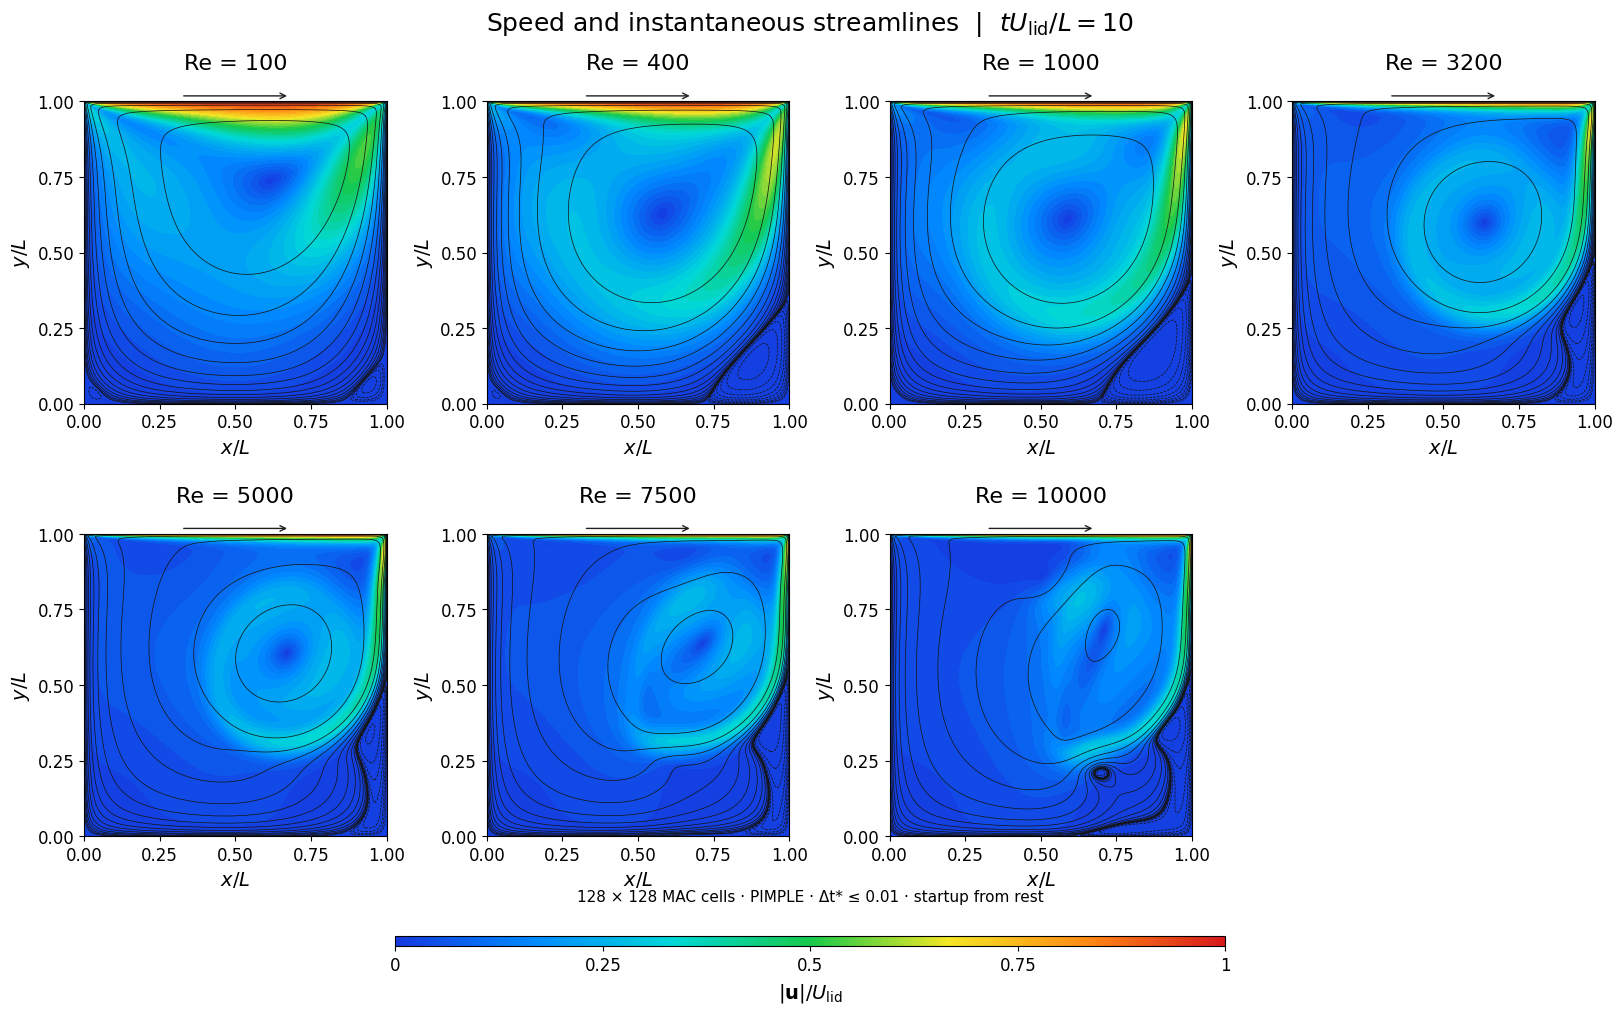

In [4]:
TIME_TO_VIEW = 10.0
FIELD_TO_VIEW = "speed"
index = int(np.argmin(np.abs(retained[0]["times"] - TIME_TO_VIEW)))
actual = retained[0]["times"][index]
print(f"Requested t*={TIME_TO_VIEW:g}; showing actual stored t*={actual:g}")
fig, _, _ = comparison_figure(retained, FIELD_TO_VIEW, index,
    common_field_bounds(retained), streamfunction_levels(retained))
display(fig); plt.close(fig)

Two useful quantitative observables are kinetic energy per unit area,
$E^*=\tfrac12\int_0^1\int_0^1(u^{*2}+v^{*2})\,dx^*dy^*$, and the minimum of $\psi^*$,
which measures the strength of the main clockwise circulation in this sign convention.
The grid node containing that minimum estimates the primary vortex center; its position
is discrete, so a one-cell jump need not represent a sudden physical jump.

Comparing at equal $t^*$ is a controlled physical comparison, not a claim that every
Reynolds number has completed the same fraction of its equilibration. The viscous
diffusion time scales as $L^2/\nu$, or $Re$ in these time units. Convection and wall-layer
formation also matter, so do not infer a steady state from that timescale alone.

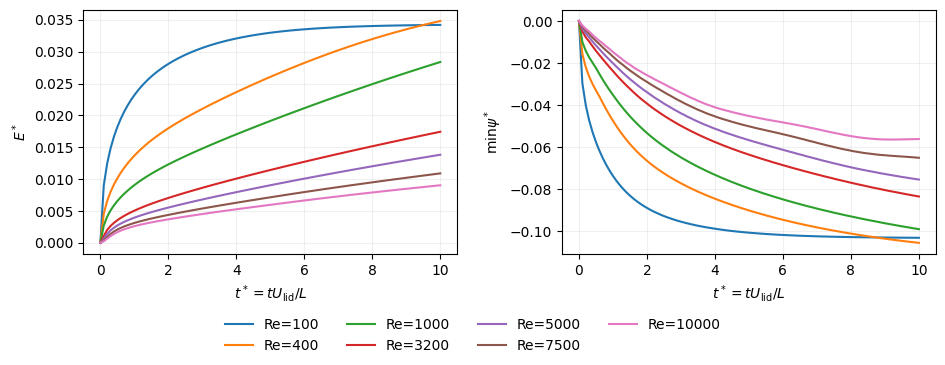

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for result in retained:
    data = [frame_fields(result, k) for k in range(len(result["times"]))]
    re = result["config"]["reynolds"]
    axes[0].plot(result["times"], [d["kinetic_energy"] for d in data], label=f"Re={re:g}")
    axes[1].plot(result["times"], [d["psi_min"] for d in data])
axes[0].set_ylabel(r"$E^*$")
axes[1].set_ylabel(r"$\min\psi^*$")
for ax in axes:
    ax.set_xlabel(r"$t^*=tU_{\mathrm{lid}}/L$")
    ax.grid(alpha=.18)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, frameon=False)
fig.subplots_adjust(bottom=.27, wspace=.28)
display(fig); plt.close(fig)

## 5. Run your own small startup on a CPU

The next cell performs a genuinely fresh solve. Its $16\times16$ mesh and short duration
are a quick learning experiment, **not** the seven-case retained production setting.
Increase one control at a time. For all seven retained Reynolds numbers, set `RUN_FRESH`
and choose a value from `RE_MENU`; high-$Re$ coarse runs may be visibly mesh sensitive.

| Control | What changes | What to hold fixed when studying it |
|---|---|---|
| `CELLS` | Spatial resolution and cost | Physical end time, observation times, method, $Re$ |
| `DT` | Temporal resolution | Mesh and sufficient within-step corrections |
| `END_TIME` | Duration of startup | Do not compare different final times as identical states |
| `FRAME_INTERVAL` | Saved/movie sampling | Use a multiple of `DT` for a pure storage-frequency change |
| `OUTER`, `PRESSURE` | Within-step coupling work | Mesh, timestep and physical end time |
| `METHOD` | `piso` or `pimple` coupling | Same physical timestep, mesh and end time |

If a frame interval is not a multiple of the timestep, the solver shortens real steps to
hit the frames; changing that interval then also changes the actual integration schedule.

,0
frames,1.100000e+01
actual_steps,1.000000e+01
end_time,2.000000e-01
runtime_seconds,3.706903e-01
max_divergence_linf,1.963707e-15
max_time_step_momentum_defect_linf,1.580896e-05
last_steady_momentum_defect_linf,1.288651e+00
max_pressure_mean_abs,4.770490e-18
max_cfl,2.252137e-01


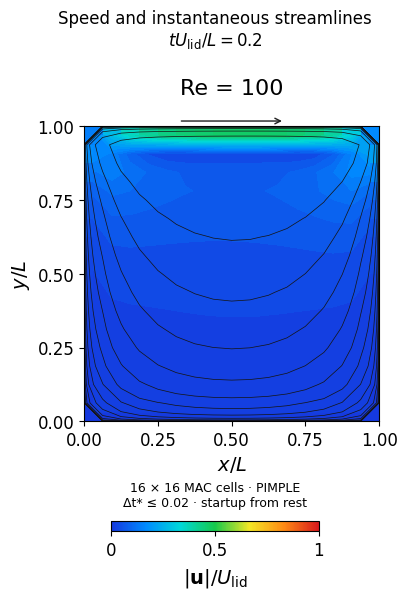

In [6]:
RUN_FRESH = True
RE, CELLS, DT, END_TIME, FRAME_INTERVAL = 100, 16, .02, .2, .02
METHOD = "pimple"
OUTER, PRESSURE = 3, 2
if RUN_FRESH:
    config = ExperimentalConfig(method=METHOD, reynolds=RE, cells=CELLS,
        dt=DT, end_time=END_TIME, outer_correctors=OUTER,
        pressure_correctors=PRESSURE, max_iterations=100000)
    fresh = simulate_startup(config, observation_times(END_TIME, FRAME_INTERVAL))
    display(pd.DataFrame([case_summary(fresh)]).drop(columns=["config", "qualification"]).T)
    fig, _, _ = comparison_figure([fresh], "speed", -1)
    display(fig); plt.close(fig)

## 6. Timestep, corrector and grid sensitivity

The retained baseline audit at $Re=1000$ and $7500$ changes one control at a time: 32 versus
64 cells, $\Delta t^*=0.02$ versus $0.01$, and 3 outer/2 pressure corrections versus
6 outer/4 pressure corrections. Each pair has exactly matching physical frame times.
Mesh comparison samples the fine-grid field at coarse cell centers solely to measure
the difference. Each movie and retained scientific payload keeps its native grid.

For velocity use $\delta_u=\sqrt{\langle(u_a-u_b)^2+(v_a-v_b)^2\rangle}$ and
$\delta_u/\sqrt{\langle u_b^2+v_b^2\rangle}$ where the denominator is nonzero.
At rest the relative value is undefined and is displayed as missing, not fabricated as zero.
Pressure and vorticity RMS differences retain their dimensionless units and declared gauge.
These are observed numerical sensitivities, not rigorous error bounds or independent truth.
The 32-to-64-cell velocity differences at $t^*=10$ were approximately 13.2% at $Re=1000$
and 77.6% at $Re=7500$, much larger than the corresponding timestep/corrector changes.
This motivated finer-mesh trajectories, not a claim that 64 cells were converged.

,Re,t*,velocity relative L2 difference,pressure RMS difference,vorticity RMS difference
study,,,,,
Re1000_mesh32,1000,10.0,0.132223,7.153331e-03,1.736882
Re1000_dt_half,1000,10.0,0.002136,1.052492e-04,0.005899
Re1000_correctors,1000,10.0,0.000006,2.470560e-07,0.000018
Re7500_mesh32,7500,10.0,0.776464,8.883910e-03,2.632680
Re7500_dt_half,7500,10.0,0.026808,3.177195e-04,0.076212
Re7500_correctors,7500,10.0,0.000322,4.457159e-06,0.000956
Re100_grid64_128,100,10.0,0.011815,1.025799e-02,0.851694
Re400_grid64_128,400,10.0,0.020883,3.238796e-03,1.017210
Re1000_grid64_128,1000,10.0,0.044942,2.880266e-03,1.379706


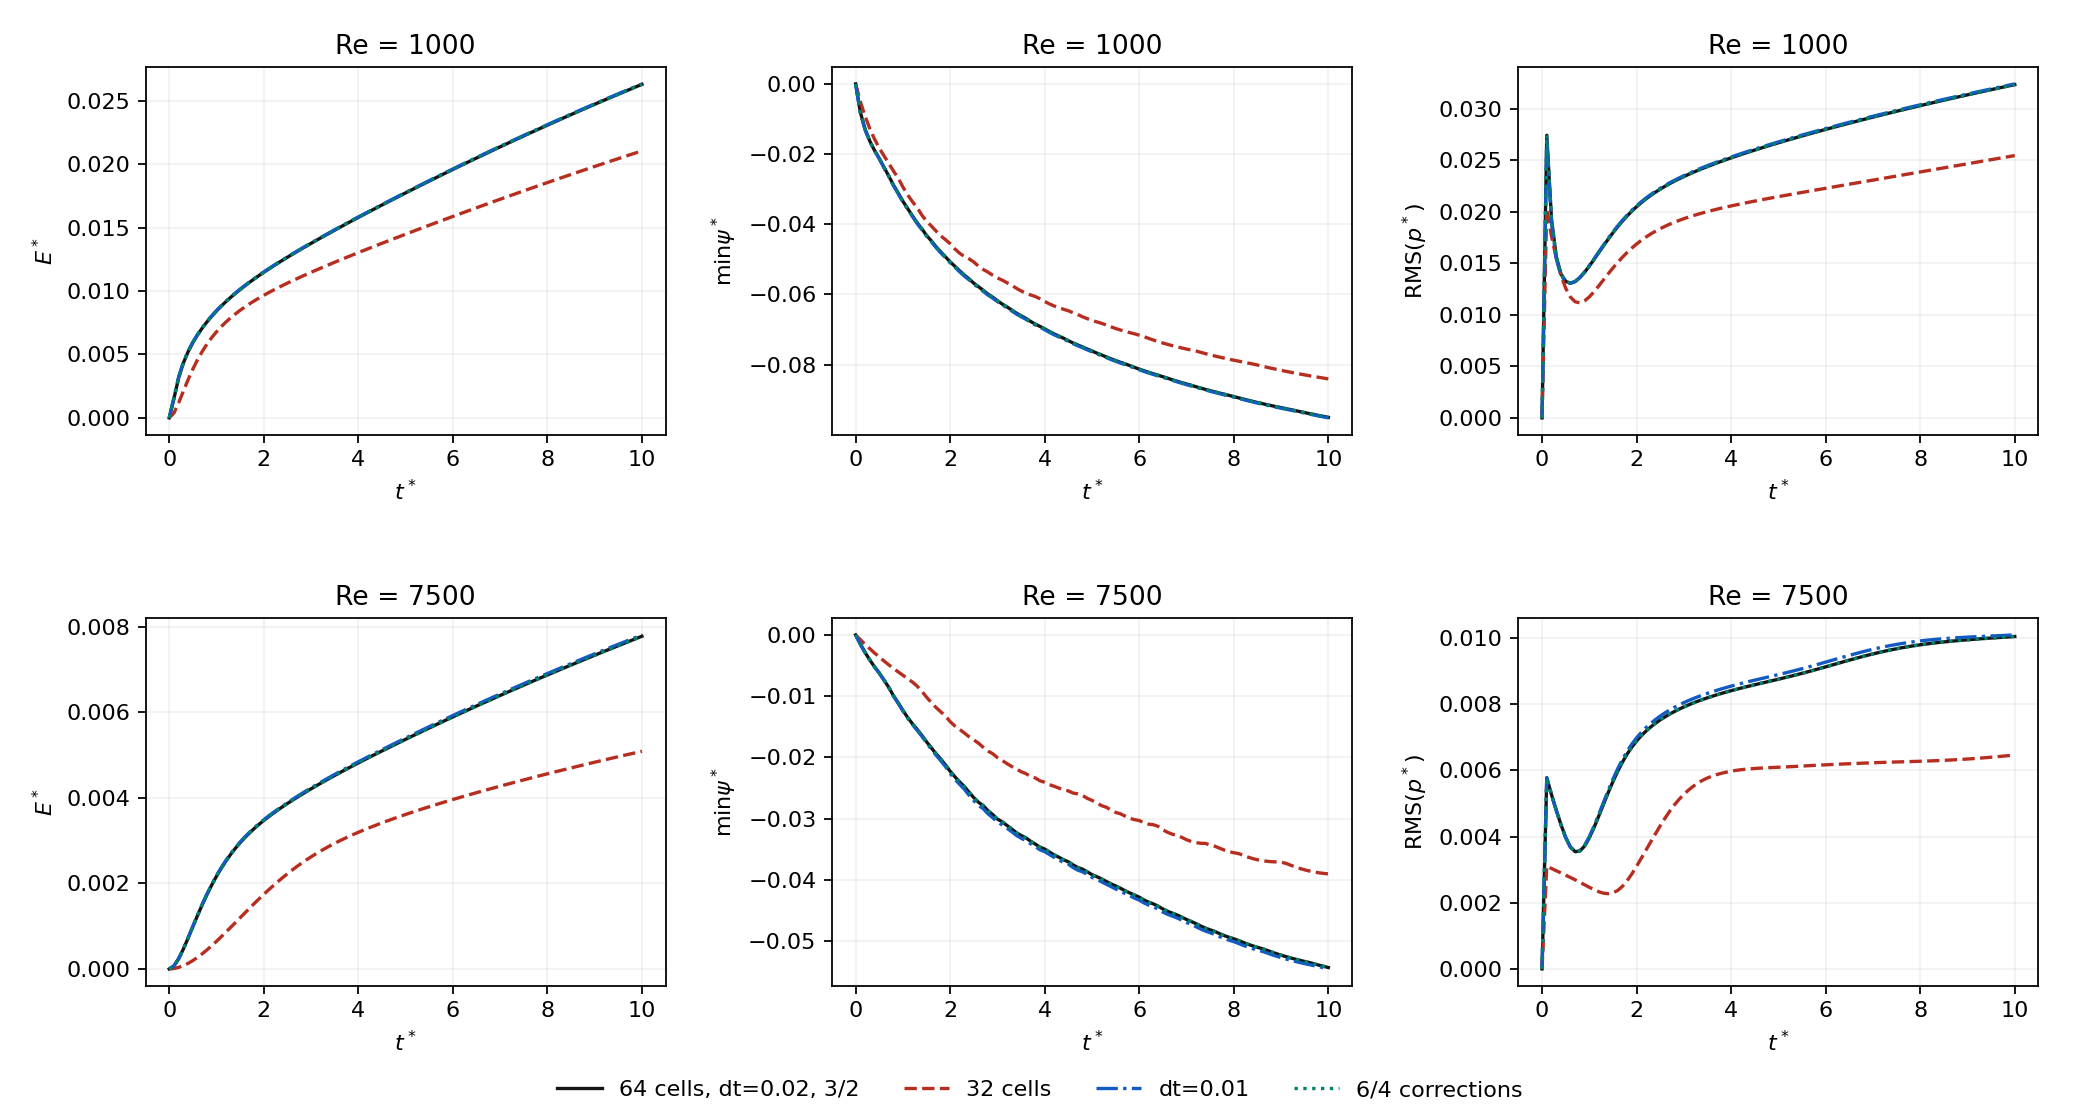

**Matched-timestep 64 versus 128 cells: physical profiles at t*=10.**

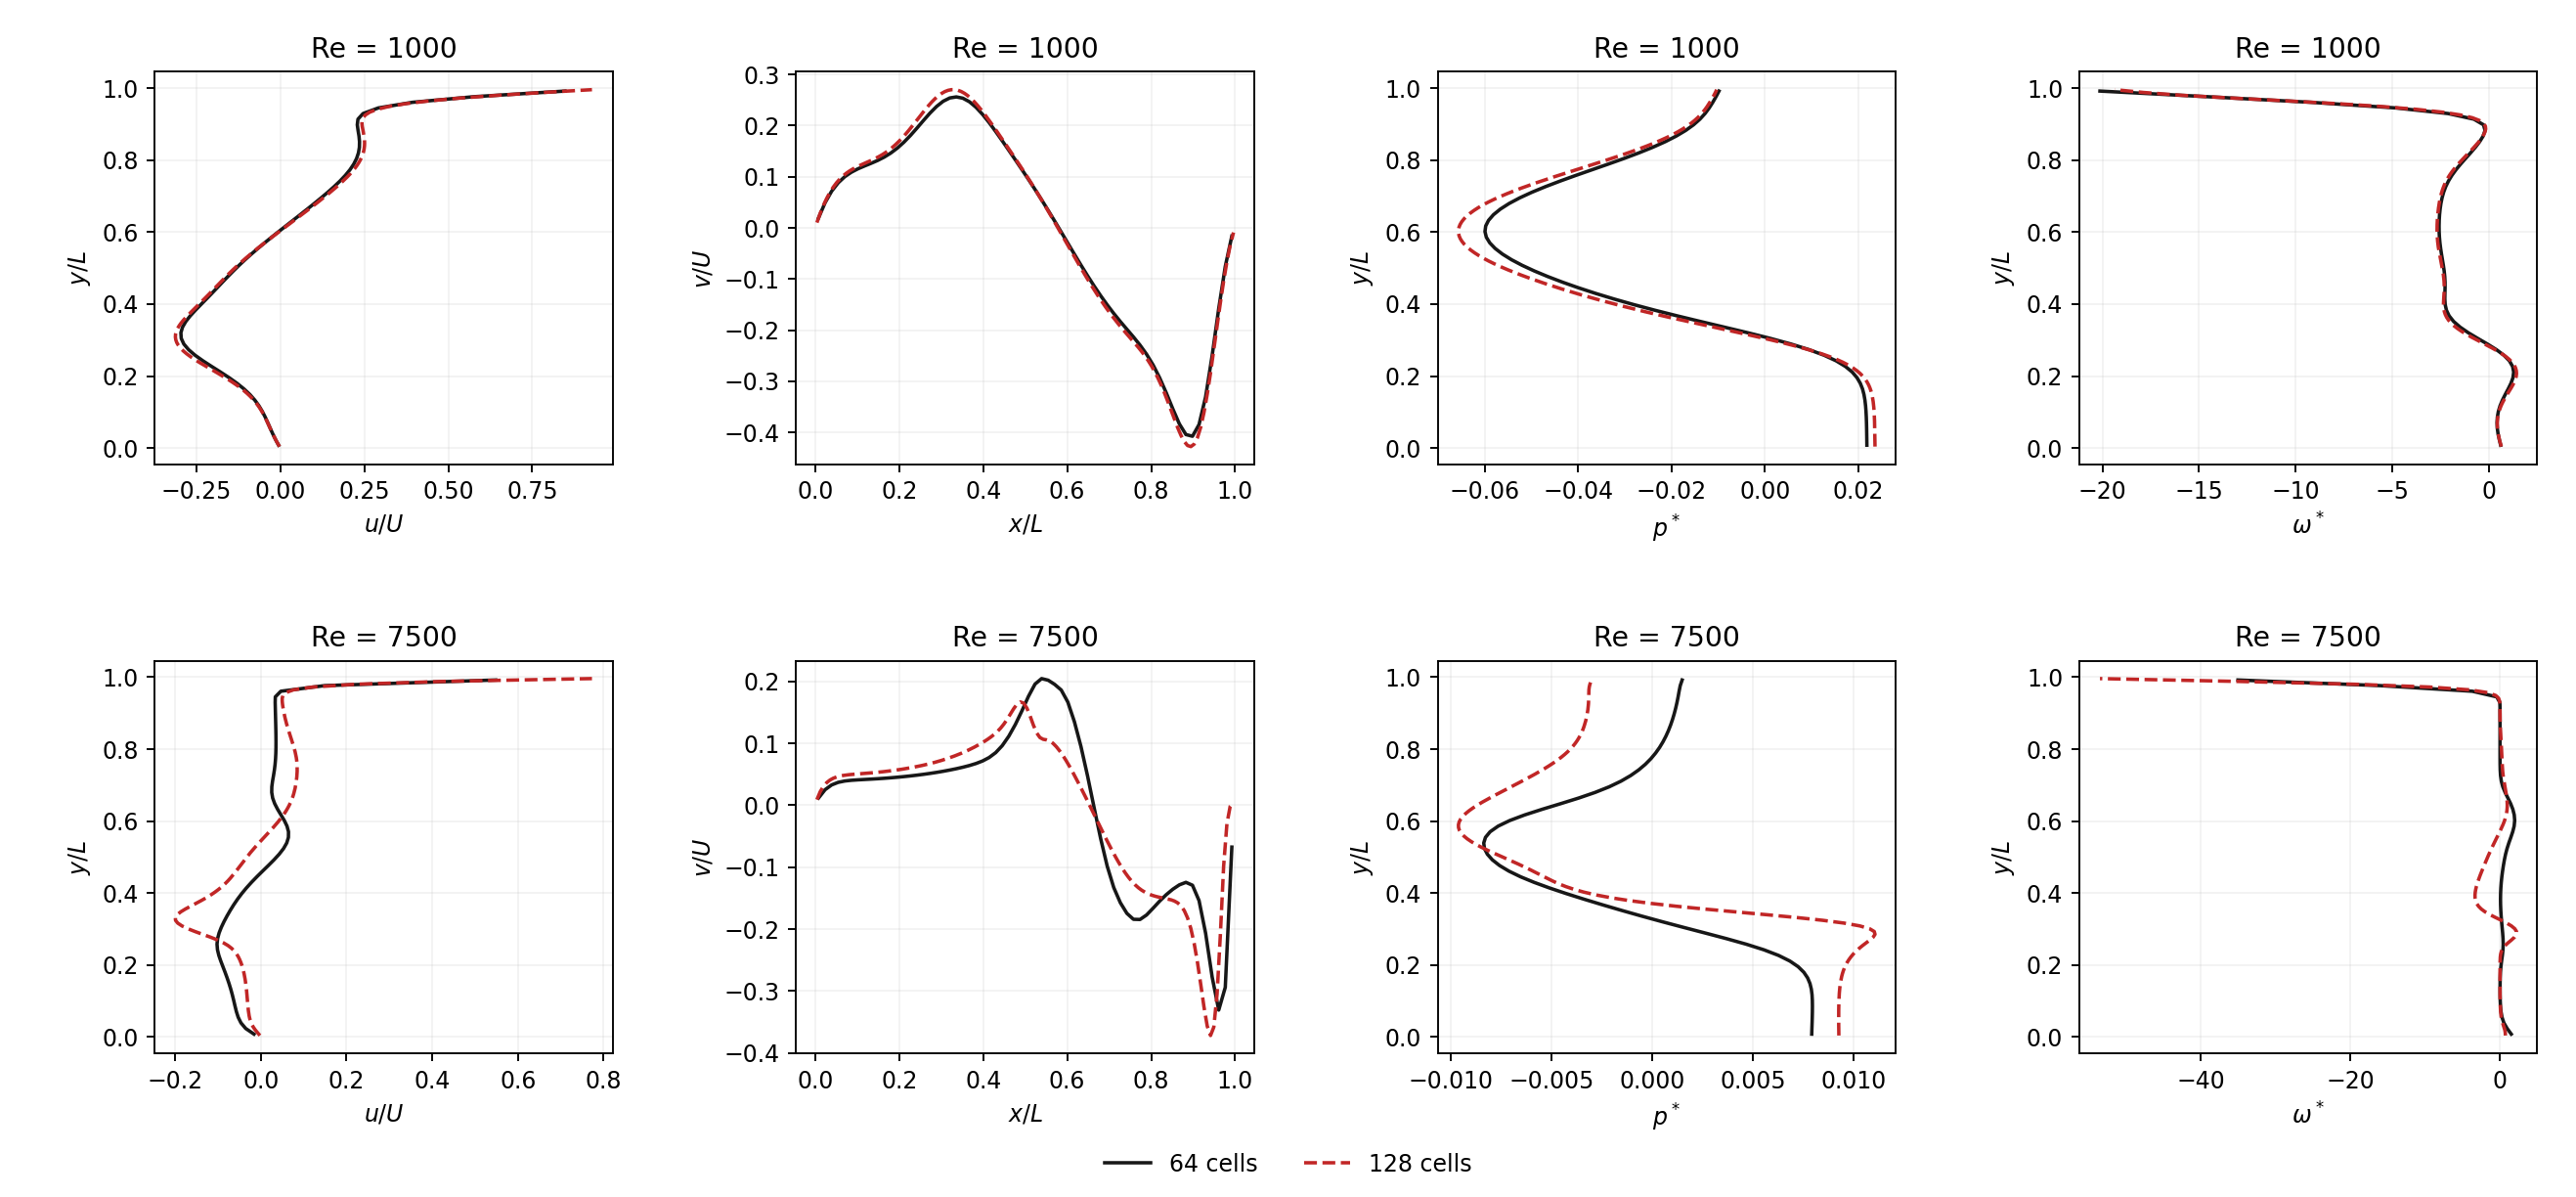

In [7]:
sensitivity = json.loads((RESULTS / "sensitivity.json").read_text())
table = []
for label, report in sensitivity["comparisons"].items():
    row = report["frames"][-1]
    table.append({"study": label, "Re": report["candidate"]["reynolds"],
        "t*": row["time"], "velocity relative L2 difference": row["velocity_relative_l2"],
        "pressure RMS difference": row["pressure_rms_difference"],
        "vorticity RMS difference": row["vorticity_rms_difference"]})
display(pd.DataFrame(table).set_index("study"))
display(Image(filename=str(RESULTS / "media/sensitivity_profiles.png")))
if (RESULTS / "media/grid_refinement_profiles.png").exists():
    display(Markdown("**Matched-timestep 64 versus 128 cells: physical profiles at t*=10.**"))
    display(Image(filename=str(RESULTS / "media/grid_refinement_profiles.png")))

## 7. Export a new movie without changing scientific data

FFmpeg is required only for MP4 export, not the solver. Colab normally provides it;
a local machine can install FFmpeg or set `FLOWMLLAB_FFMPEG` to its executable.
The command below is an optional longer rerun. Use a new directory for each experiment;
the driver refuses to overwrite a completed scientific trajectory. Store configuration,
native fields and checksums together. Reuse the existing MP4s for a presentation if you
have not run your own matched experiment.

```python
# Run from ROOT. This is a longer, optional computation, not the quick default.
out = ROOT / "results/cavity_startup/student_experiment"
subprocess.run([sys.executable, "qa/build_cavity_startup.py", "solve",
    "--reynolds", "100", "--cells", "32", "--dt", ".02",
    "--end-time", "4", "--interval", ".1", "--output", str(out)], cwd=ROOT, check=True)
subprocess.run([sys.executable, "qa/build_cavity_startup.py", "render",
    "--input", str(out), "--output", str(out), "--reynolds", "100"], cwd=ROOT, check=True)
```

## 8. Student work - measurable deliverables

1. **Timeline and mechanism.** At $Re=100,400,1000$, inspect $t^*=0.2,1,4,10$.
   Submit one matched speed/streamline plate, an energy-versus-time plot and a paragraph
   explaining how wall shear starts circulation. Use the actual frame time in each caption.
2. **Vortex formation.** Track the primary streamfunction minimum and its $(x/L,y/L)$
   location. Mark a candidate secondary cell by closed contours and a local extremum of
   the opposite sign. Record its position, signed $\psi^*$ and first sampled appearance
   time; this time is only bracketed by the frame interval. Verify with mesh and timestep
   refinement before calling it resolved. A faint color patch is not sufficient evidence.
3. **Timestep study.** At one moderate $Re$, compare `DT=.02` and `.01` at identical
   physical times and fixed mesh. Plot both centerline velocity profiles and the energy
   curves. Report the final relative velocity difference and measured CPU time.
4. **Coupling study.** Hold `DT` fixed; compare PISO, PIMPLE 3/2 and PIMPLE 6/4 corrections.
   Compare momentum-step defects, continuity and physical profiles. Explain why small
   continuity alone did not establish accuracy and why more corrections cost time.
5. **Grid study.** Compare 16,32 and, if affordable,64 cells at one common time. Overlay
   $u(x/L=0.5,y/L)$ and $v(x/L,y/L=0.5)$, record vortex locations and pressure extrema,
   and distinguish spatial sensitivity from timestep/coupling sensitivity. Preserve all
   three results even if the coarsest field looks poor.
6. **Pressure and sign.** Plot one vertical pressure profile at two physical times and
   demonstrate that adding a spatial constant changes no pressure gradient. Explain
   why the shared zero-mean gauge is required before comparing plotted pressure values.
7. **High-$Re$ claim audit.** Choose 3200,5000,7500 or10000. State the evidence needed
   before describing a small visible cell as resolved or a finite-time frame as steady.
   Compare the available 7500 refinement results. Do not label these 2D finite-time
   pictures as validated three-dimensional turbulence.
8. **Submission.** Provide a short report, three short movies or selected physical-time
   frames, a table of exact controls/costs/sensitivities, and your configuration plus
   compact trajectory files. No bar chart is needed: show physical profiles and time histories.

**Read further.** Ghia, Ghia & Shin (1982), *Journal of Computational Physics* 48,387-411,
[DOI](https://doi.org/10.1016/0021-9991(82)90058-4), is the steady benchmark source.
The preceding Week1.2 lecture derives the shared MAC pressure-correction algorithm.

## 9. Continue startup and test stationarity

The movies stop at t⋆ = tU/L = 10; that is a startup observation time, not evidence
that the flow has become steady. The [stationarity guide](https://github.com/Ehsan-Roohi/FlowMLLab/blob/main/docs/CAVITY_STARTUP_STATIONARITY.md)
gives optional CPU commands to resume verified native fields to absolute times
25, 50 and 100, with complete checkpoints and three full physical-window tests.
These longer runs are optional and are not started by **Run all**.

The guide adds five investigations: matched-time profiles; window means versus
instantaneous fields; timestep and mesh sensitivity; a separate tighter-coupling
confirmation; and interpretation of fixed corner probes, which are not tracked
vortex centers. Keep a fixed-grid stationarity candidate, a 6/4-correction
confirmation, and timestep/mesh accuracy as separate conclusions. A high-Re case
may remain unresolved or unsteady; no result here requires every case to settle.